<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 57.0MB/s]


Dataset ready: /content/HPV2025.xlsx
Dataset size (KB): 64.49
Rows available: 588
Predictors: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
SMOTE: False
Target class counts:
HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: 381 rows | class counts: {0: 37, 1: 344}
Validation: 89 rows | class counts: {0: 9, 1: 80}
Test: 118 rows | class counts: {0: 12, 1: 106}
Original predictor count: 8
Encoded feature count: 23
Automatic class weights: [5.14864865 0.55377907]
SMOTE: False
CNNClassifier(
  (conv): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=368, out_features=32, bias=True)
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (fc3): Linear(in_features=16, out_features=2, bias=True)
)
Epoch 001/500 | train loss=0.6897 | val loss=0.7064 | val ROC-AUC=0.4986 | val PR-AUC=0.9026 | val balanced acc

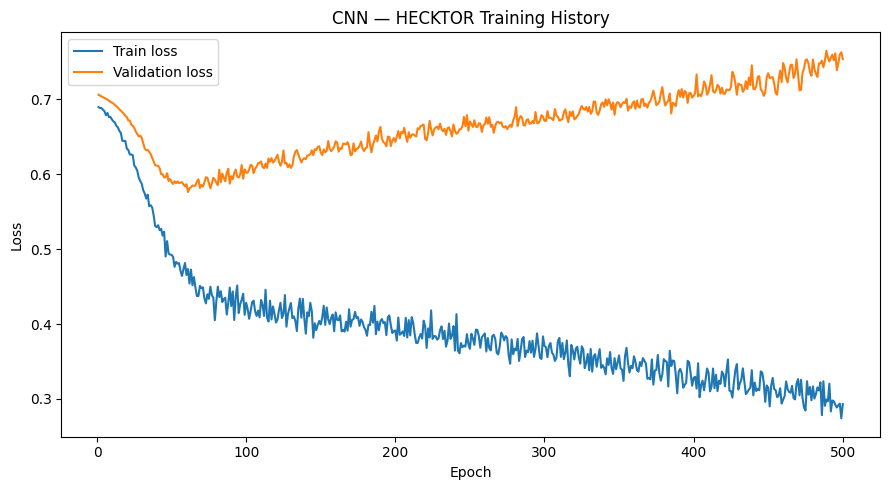


CHECKPOINT: best_val_loss
Epoch: 61
Threshold: 0.595

TEST METRICS
Checkpoint                      best_val_loss
Checkpoint_Epoch                           61
Validation_Loss                       0.57637
Validation_ROC_AUC                   0.786111
Validation_PR_AUC                    0.971892
Validation_Balanced_Accuracy         0.751389
Threshold                               0.595
Accuracy                             0.694915
Balanced_Accuracy                     0.68239
Precision                            0.948718
Recall                               0.698113
F1                                   0.804348
ROC_AUC                              0.756289
PR_AUC                               0.963528

Confusion matrix:
[[ 8  4]
 [32 74]]

Classification report:
              precision    recall  f1-score   support

           0       0.20      0.67      0.31        12
           1       0.95      0.70      0.80       106

    accuracy                           0.69       118
   macro

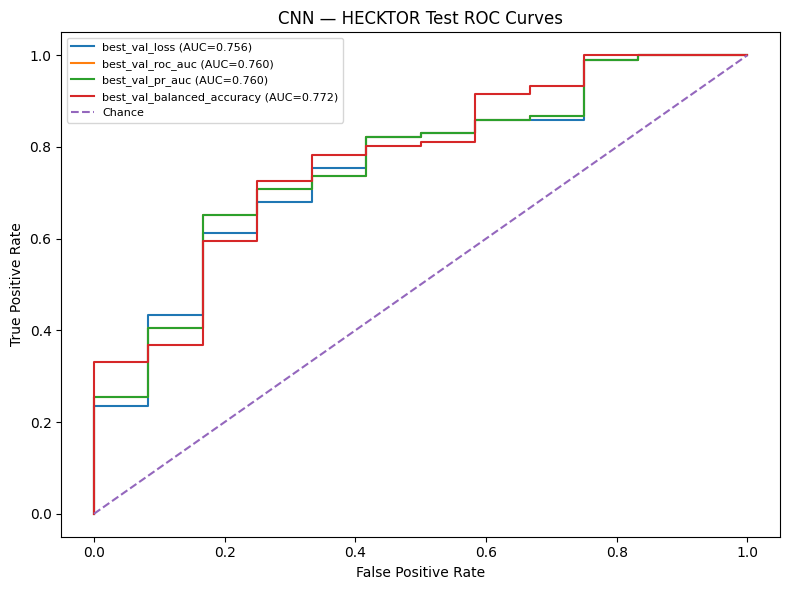

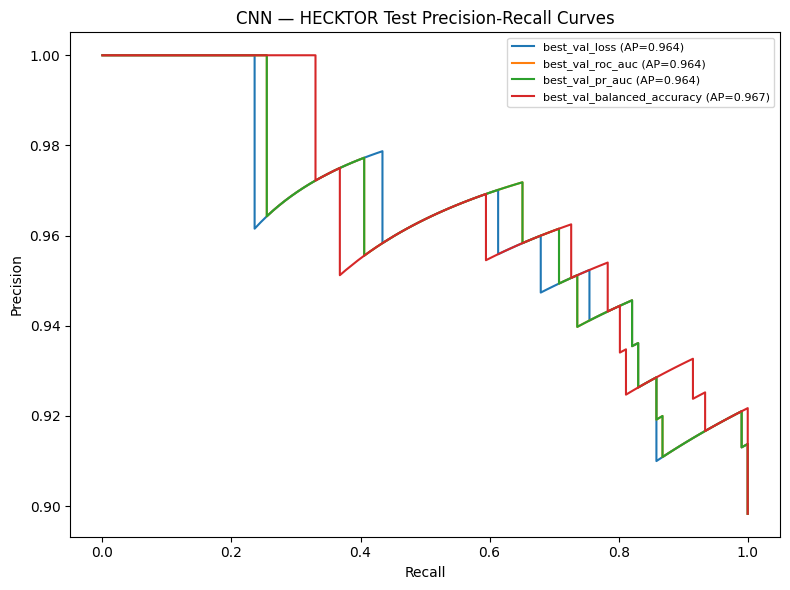


CNN — HECKTOR TEST SET CHECKPOINT COMPARISON
                Checkpoint  Checkpoint_Epoch  Threshold  Accuracy  Balanced_Accuracy  Precision   Recall       F1  ROC_AUC   PR_AUC
             best_val_loss                61      0.595  0.694915           0.682390   0.948718 0.698113 0.804348 0.756289 0.963528
          best_val_roc_auc                50      0.580  0.711864           0.728774   0.961538 0.707547 0.815217 0.760220 0.964367
           best_val_pr_auc                50      0.580  0.711864           0.728774   0.961538 0.707547 0.815217 0.760220 0.964367
best_val_balanced_accuracy                27      0.565  0.635593           0.686321   0.956522 0.622642 0.754286 0.772013 0.966603

Saved results to: /content/CNN_results_HECKTOR
Saved checkpoints to: /content/CNN_results_HECKTOR/checkpoints

Output files:
 - CNN_epoch_history.csv
 - CNN_results.csv
 - CNN_test_predictions.csv
 - checkpoint_summary.csv
 - checkpoints
 - cnn_preprocessor.joblib
 - metrics.csv
 - metrics_al

In [8]:
# ============================================================
# CNN — HECKTOR HPV CLASSIFIER
# Hancock-aligned methodology | Seed 42 | No SMOTE
# 8 predictors | 65/15/20 split | 500 epochs
# Four validation-selected checkpoints
# ============================================================

!pip -q install gdown

import os
import json
import random
import copy
import warnings
import joblib
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gdown

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 32


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
# 2. DOWNLOAD AND LOAD HECKTOR DATA
# ============================================================

# Download directly; no Google Drive mount is required.
BASE = "/content"
DATA_PATH = "/content/HPV2025.xlsx"
OUT_DIR = os.path.join(BASE, "CNN_results_HECKTOR")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

FILE_ID = "1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv"

if not os.path.isfile(DATA_PATH):
    print("Downloading HPV2025.xlsx from Google Drive...")

    downloaded = gdown.download(
        id=FILE_ID,
        output=DATA_PATH,
        quiet=False
    )

    if downloaded is None or not os.path.isfile(DATA_PATH):
        raise FileNotFoundError(
            "Could not download HPV2025.xlsx. "
            "Check the Google Drive file ID and sharing permissions."
        )

if not os.path.isfile(DATA_PATH) or os.path.getsize(DATA_PATH) == 0:
    raise FileNotFoundError(
        f"Dataset is missing or empty: {DATA_PATH}"
    )

print("Dataset ready:", DATA_PATH)
print("Dataset size (KB):", round(os.path.getsize(DATA_PATH) / 1024, 2))

df = pd.read_excel(DATA_PATH)

target_col = "HPV Status"

if target_col not in df.columns:
    raise KeyError(
        f"Missing target column '{target_col}'. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove rows without a target before modelling.
df = df.dropna(subset=[target_col]).copy()

# Preserve patient identifiers for result exports only.
id_col = next(
    (c for c in ["PatientID", "patient_id"] if c in df.columns),
    None
)

if id_col is None:
    patient_ids = pd.Series(
        np.arange(len(df)),
        index=df.index,
        name="patient_id"
    )
else:
    patient_ids = df[id_col].copy()

# Do not use IDs or unrelated task columns as predictors.
df = df.drop(
    columns=[
        "PatientID",
        "patient_id",
        "CenterID",
        "Task 1",
        "Task 2",
        "Task 3"
    ],
    errors="ignore"
)

# The eight specified HECKTOR predictors.
features = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

numeric_features = ["Age"]

categorical_features = [
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing_features = [
    col for col in features if col not in df.columns
]

if missing_features:
    raise KeyError(
        f"Missing predictor columns: {missing_features}\n"
        f"Available columns: {df.columns.tolist()}"
    )


# ------------------------------------------------------------
# Normalize HPV Status to binary labels: negative=0, positive=1
# ------------------------------------------------------------

def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value_str = str(value).strip().lower()

    if value_str in {
        "negative", "neg", "0", "0.0", "false", "no"
    }:
        return 0

    if value_str in {
        "positive", "pos", "1", "1.0", "true", "yes"
    }:
        return 1

    try:
        number = float(value_str)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

if df["HPV_Label"].nunique() != 2:
    raise ValueError(
        "HPV Status must contain both classes, 0 and 1, "
        "after label normalization."
    )

# Identifiers are retained for output but never enter the model.
df = df[features + ["HPV_Label"]].copy()
df["patient_id"] = patient_ids.reindex(df.index).values

print("Rows available:", len(df))
print("Predictors:", features)
print("SMOTE: False")
print("Target class counts:")
print(df["HPV_Label"].value_counts().sort_index())


# ============================================================
# 3. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# Same proportions and random seed as Hancock:
# 80% development data / 20% test,
# then 15% of the full dataset for validation.
train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train = train.reset_index(drop=True)
val = val.reset_index(drop=True)
test = test.reset_index(drop=True)

for name, frame in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        f"{name}: {len(frame)} rows | "
        f"class counts: "
        f"{frame['HPV_Label'].value_counts().sort_index().to_dict()}"
    )


# ============================================================
# 4. IMPUTATION, ONE-HOT ENCODING AND SCALING
# ============================================================

X_train_df = train[features].copy()
X_val_df = val[features].copy()
X_test_df = test[features].copy()

# Clean numeric and categorical values.
for frame in [X_train_df, X_val_df, X_test_df]:

    for col in numeric_features:
        frame[col] = pd.to_numeric(
            frame[col],
            errors="coerce"
        )

    for col in categorical_features:
        frame[col] = (
            frame[col]
            .astype("object")
            .replace(r"^\s*$", np.nan, regex=True)
            .replace(["nan", "None", "NaN"], np.nan)
        )

# Fit imputation values using training data only.
for col in numeric_features:
    median_value = X_train_df[col].median()

    if pd.isna(median_value):
        median_value = 0.0

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = frame[col].fillna(median_value)

for col in categorical_features:
    mode_values = X_train_df[col].mode(dropna=True)

    fill_value = (
        str(mode_values.iloc[0])
        if not mode_values.empty
        else "Unknown"
    )

    for frame in [X_train_df, X_val_df, X_test_df]:
        frame[col] = (
            frame[col]
            .fillna(fill_value)
            .astype(str)
            .replace(["", "nan", "None", "NaN"], "Unknown")
        )

# One-hot encode categorical predictors.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    # Compatibility with older scikit-learn versions.
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Standardize Age; one-hot encode all other predictors.
preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_features
    ),
    (
        "categorical",
        encoder,
        categorical_features
    )
])

# Fit on training data only; transform validation and test.
X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

y_train = train["HPV_Label"].to_numpy(dtype=np.int64)
y_val = val["HPV_Label"].to_numpy(dtype=np.int64)
y_test = test["HPV_Label"].to_numpy(dtype=np.int64)

print("Original predictor count:", len(features))
print("Encoded feature count:", X_train.shape[1])


# ============================================================
# 5. AUTOMATIC CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both HPV classes must be present in the training split."
    )

# Inverse-frequency class weights calculated on training data only.
weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Automatic class weights:", weights)
print("SMOTE: False")


# ============================================================
# 6. TENSORS AND TRAINING DATA LOADER
# ============================================================

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val,
    dtype=torch.float32,
    device=device
)

y_val_t = torch.tensor(
    y_val,
    dtype=torch.long,
    device=device
)

X_test_t = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=device
)


# ============================================================
# 7. DEFINE HANCOCK-ALIGNED CNN ARCHITECTURE
# ============================================================

class CNNClassifier(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.conv = nn.Conv1d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.25)

        self.fc1 = nn.Linear(input_dim * 16, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 2)

    def forward(self, x):
        # Shape: (batch, predictors)
        x = x.unsqueeze(1)

        x = self.conv(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = x.flatten(start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)
        x = self.relu(x)

        x = self.fc3(x)

        return x


model = CNNClassifier(
    input_dim=X_train.shape[1]
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    reduction="none"
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print(model)


# ============================================================
# 8. VALIDATION HELPERS AND CHECKPOINT RULES
# ============================================================

thresholds = np.linspace(0.10, 0.90, 161)


def select_threshold(y_true, probabilities):
    """Maximize validation balanced accuracy; ties closest to 0.5."""

    scores = [
        balanced_accuracy_score(
            y_true,
            (probabilities >= threshold).astype(int)
        )
        for threshold in thresholds
    ]

    best_score = max(scores)

    best_threshold = min(
        (
            threshold
            for threshold, score in zip(thresholds, scores)
            if np.isclose(score, best_score)
        ),
        key=lambda threshold: abs(threshold - 0.5)
    )

    return float(best_threshold), float(best_score)


def predict_probabilities(model, X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


def validation_metrics(model):
    probabilities = predict_probabilities(model, X_val_t)

    threshold, balanced_acc = select_threshold(
        y_val,
        probabilities
    )

    roc_auc = (
        roc_auc_score(y_val, probabilities)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    pr_auc = average_precision_score(
        y_val,
        probabilities
    )

    return {
        "probabilities": probabilities,
        "threshold": threshold,
        "balanced_accuracy": float(balanced_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(pr_auc)
    }


checkpoint_specs = {
    "best_val_loss": {
        "filename": "cnn_best_val_loss.pt"
    },
    "best_val_roc_auc": {
        "filename": "cnn_best_val_roc_auc.pt"
    },
    "best_val_pr_auc": {
        "filename": "cnn_best_val_pr_auc.pt"
    },
    "best_val_balanced_accuracy": {
        "filename": "cnn_best_val_balanced_accuracy.pt"
    }
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


def save_checkpoint(name, epoch, val_loss, result):
    checkpoint = {
        "model_state_dict": copy.deepcopy(model.state_dict()),
        "epoch": int(epoch),
        "validation_loss": float(val_loss),
        "validation_roc_auc": float(result["roc_auc"]),
        "validation_pr_auc": float(result["pr_auc"]),
        "validation_balanced_accuracy": float(
            result["balanced_accuracy"]
        ),
        "validation_threshold": float(result["threshold"])
    }

    torch.save(
        checkpoint,
        os.path.join(
            CHECKPOINT_DIR,
            checkpoint_specs[name]["filename"]
        )
    )


# ============================================================
# 9. TRAIN FOR ALL 500 EPOCHS — NO EARLY STOPPING
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()
    running_loss = 0.0
    seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)

        per_example_loss = criterion(logits, yb)
        loss = per_example_loss.mean()

        loss.backward()
        optimizer.step()

        running_loss += per_example_loss.detach().sum().item()
        seen += len(yb)

    train_loss = running_loss / max(seen, 1)

    # Validation after each epoch.
    model.eval()

    with torch.no_grad():
        val_loss = criterion(
            model(X_val_t),
            y_val_t
        ).mean().item()

    result = validation_metrics(model)

    history.append({
        "epoch": epoch,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": result["roc_auc"],
        "val_pr_auc": result["pr_auc"],
        "val_balanced_accuracy": result["balanced_accuracy"],
        "val_threshold": result["threshold"]
    })

    # Checkpoint 1: lowest validation loss.
    if val_loss < best_values["best_val_loss"]:
        best_values["best_val_loss"] = float(val_loss)
        best_epochs["best_val_loss"] = epoch

        save_checkpoint(
            "best_val_loss",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 2: highest validation ROC-AUC.
    if (
        np.isfinite(result["roc_auc"])
        and result["roc_auc"] > best_values["best_val_roc_auc"]
    ):
        best_values["best_val_roc_auc"] = float(result["roc_auc"])
        best_epochs["best_val_roc_auc"] = epoch

        save_checkpoint(
            "best_val_roc_auc",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 3: highest validation PR-AUC.
    if (
        np.isfinite(result["pr_auc"])
        and result["pr_auc"] > best_values["best_val_pr_auc"]
    ):
        best_values["best_val_pr_auc"] = float(result["pr_auc"])
        best_epochs["best_val_pr_auc"] = epoch

        save_checkpoint(
            "best_val_pr_auc",
            epoch,
            val_loss,
            result
        )

    # Checkpoint 4: highest validation balanced accuracy.
    if (
        result["balanced_accuracy"]
        > best_values["best_val_balanced_accuracy"]
    ):
        best_values["best_val_balanced_accuracy"] = float(
            result["balanced_accuracy"]
        )
        best_epochs["best_val_balanced_accuracy"] = epoch

        save_checkpoint(
            "best_val_balanced_accuracy",
            epoch,
            val_loss,
            result
        )

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d}/{MAX_EPOCHS} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val ROC-AUC={result['roc_auc']:.4f} | "
            f"val PR-AUC={result['pr_auc']:.4f} | "
            f"val balanced accuracy="
            f"{result['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs, but ran {len(history)}."
    )

print("Training completed:", len(history), "epochs")
print("Best checkpoint epochs:", best_epochs)

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

history_df.to_csv(
    os.path.join(OUT_DIR, "CNN_epoch_history.csv"),
    index=False
)


# ============================================================
# 10. PLOT TRAINING HISTORY
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN — HECKTOR Training History")
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)

plt.show()


# ============================================================
# 11. EVALUATE ALL FOUR CHECKPOINTS ON THE TEST SET
# ============================================================

all_test_metrics = []
all_test_predictions = []
checkpoint_summary = []

for checkpoint_name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])

    # Threshold is selected using validation data only.
    val_prob = predict_probabilities(model, X_val_t)

    threshold, val_ba = select_threshold(
        y_val,
        val_prob
    )

    # Evaluate the selected checkpoint on the test set.
    test_prob = predict_probabilities(model, X_test_t)
    test_pred = (test_prob >= threshold).astype(int)

    test_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_ap = average_precision_score(
        y_test,
        test_prob
    )

    metrics = {
        "Checkpoint": checkpoint_name,
        "Checkpoint_Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_ba),
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_test, test_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_test, test_pred),
        "Precision": precision_score(
            y_test, test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, test_pred, zero_division=0
        ),
        "ROC_AUC": test_auc,
        "PR_AUC": test_ap
    }

    all_test_metrics.append(metrics)

    all_test_predictions.append(
        pd.DataFrame({
            "patient_id": test["patient_id"].to_numpy(),
            "y_true": y_test,
            "probability_positive": test_prob,
            "prediction": test_pred,
            "checkpoint": checkpoint_name,
            "checkpoint_epoch": int(checkpoint["epoch"]),
            "threshold": float(threshold)
        })
    )

    checkpoint_summary.append({
        "Checkpoint": checkpoint_name,
        "Epoch": int(checkpoint["epoch"]),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_ba),
        "Threshold": float(threshold)
    })

    print("\n" + "=" * 65)
    print("CHECKPOINT:", checkpoint_name)
    print("Epoch:", checkpoint["epoch"])
    print("Threshold:", round(threshold, 3))
    print("\nTEST METRICS")
    print(pd.Series(metrics).to_string())
    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, test_pred))
    print("\nClassification report:")
    print(
        classification_report(
            y_test,
            test_pred,
            zero_division=0
        )
    )


metrics_df = pd.DataFrame(all_test_metrics)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "CNN_results.csv"),
    index=False
)

metrics_df.to_csv(
    os.path.join(OUT_DIR, "metrics.csv"),
    index=False
)

predictions_df = pd.concat(
    all_test_predictions,
    ignore_index=True
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions_all_checkpoints.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "CNN_test_predictions.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(OUT_DIR, "test_predictions.csv"),
    index=False
)

checkpoint_summary_df = pd.DataFrame(checkpoint_summary)

checkpoint_summary_df.to_csv(
    os.path.join(OUT_DIR, "checkpoint_summary.csv"),
    index=False
)


# ============================================================
# 12. TEST ROC CURVES FOR ALL FOUR CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    probabilities = predict_probabilities(model, X_test_t)

    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, probabilities)
        auc_value = roc_auc_score(y_test, probabilities)

        plt.plot(
            fpr,
            tpr,
            label=f"{name} (AUC={auc_value:.3f})"
        )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN — HECKTOR Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "roc_curves_all_checkpoints.png"),
    dpi=150
)

plt.savefig(
    os.path.join(OUT_DIR, "roc_curve.png"),
    dpi=150
)

plt.show()


# ============================================================
# 13. TEST PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================

plt.figure(figsize=(8, 6))

for name, spec in checkpoint_specs.items():

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        spec["filename"]
    )

    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=False
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    probabilities = predict_probabilities(model, X_test_t)

    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_value = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP={ap_value:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN — HECKTOR Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(OUT_DIR, "pr_curves_all_checkpoints.png"),
    dpi=150
)

plt.savefig(
    os.path.join(OUT_DIR, "pr_curve.png"),
    dpi=150
)

plt.show()


# ============================================================
# 14. SAVE PREPROCESSOR AND SETTINGS
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "cnn_preprocessor.joblib")
)

settings = {
    "model": "CNN",
    "dataset": "HECKTOR",
    "seed": SEED,
    "features": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "removed_features": ["Relapse", "RFS", "Treatment"],
    "target_column": target_col,
    "target_mapping": {
        "Negative": 0,
        "Positive": 1
    },
    "class_weights": weights.tolist(),
    "smote": False,
    "early_stopping": False,
    "max_epochs": MAX_EPOCHS,
    "epochs_run": len(history),
    "batch_size": BATCH_SIZE,
    "architecture": (
        "Conv1d(1,16,kernel_size=3,padding=1)"
        "-Dropout(0.25)-FC32-FC16-FC2"
    ),
    "optimizer": "Adam",
    "learning_rate": 0.0001,
    "weight_decay": 0.0001,
    "train_size": len(train),
    "validation_size": len(val),
    "test_size": len(test),
    "checkpoint_epochs": {
        key: int(value)
        for key, value in best_epochs.items()
    },
    "checkpoint_files": {
        key: value["filename"]
        for key, value in checkpoint_specs.items()
    },
    "threshold_selection": (
        "Maximize validation balanced accuracy; "
        "ties resolved by threshold closest to 0.5"
    ),
    "test_used_for_model_selection": False
}

with open(
    os.path.join(OUT_DIR, "settings.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(settings, f, indent=2)


# ============================================================
# 15. FINAL CHECKPOINT COMPARISON AND PACKAGE RESULTS
# ============================================================

display_columns = [
    "Checkpoint",
    "Checkpoint_Epoch",
    "Threshold",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

print("\n" + "=" * 80)
print("CNN — HECKTOR TEST SET CHECKPOINT COMPARISON")
print("=" * 80)

print(metrics_df[display_columns].to_string(index=False))

print("\nSaved results to:", OUT_DIR)
print("Saved checkpoints to:", CHECKPOINT_DIR)

print("\nOutput files:")
for filename in sorted(os.listdir(OUT_DIR)):
    print(" -", filename)

print("\nCheckpoint files:")
for filename in sorted(os.listdir(CHECKPOINT_DIR)):
    print(" -", filename)

# Package results so they can be downloaded before the runtime resets.
RESULTS_ZIP = shutil.make_archive(
    OUT_DIR,
    "zip",
    root_dir=OUT_DIR
)

print("\nResults folder:", OUT_DIR)
print("Results archive:", RESULTS_ZIP)
print(
    "IMPORTANT: /content is temporary in Colab. "
    "Download the ZIP before resetting the runtime."
)

# In a separate Colab cell, run this to download the ZIP:
# from google.colab import files
# files.download(RESULTS_ZIP)